# Notebook 01 — Dreaddit Dataset Validation & Exploratory Data Analysis

**Research:** J26-IT-388 | **Component 4:** Explainable AI & Adaptive Decision Support  
**Scope:** Data verification and EDA only; **no modeling**.

The stress label is a **text annotation**, not a diagnosis or a clinically validated individual risk score. We retain the supplied train/test split and do not train or tune on test labels. Charts and metrics in this notebook describe the data only.

**Input:** `data/raw/dreaddit/dreaddit-train.csv`, `dreaddit-test.csv`  
**Outputs:** `experiments/metrics/notebook01/` and `experiments/figures/notebook01/`

Data provenance, licensing/permission and any ethical review requirements must be independently checked before sharing any raw social-media text.


## 0. Environment and project locations

In VS Code choose the **`.venv` Python kernel**. Run cells top to bottom. All paths are located relative to the Git repository; the notebook also works when launched from `notebooks/`.


In [13]:
from pathlib import Path
import json, sys, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "raw" / "dreaddit").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "raw" / "dreaddit"
OUT_METRICS = ROOT / "experiments" / "metrics" / "notebook01"
OUT_FIGS = ROOT / "experiments" / "figures" / "notebook01"
OUT_METRICS.mkdir(parents=True, exist_ok=True)
OUT_FIGS.mkdir(parents=True, exist_ok=True)
assert DATA_DIR.exists(), f"Dataset folder missing: {DATA_DIR}"
print('Python:', sys.version.split()[0], '\nProject root:', ROOT, '\nInput directory:', DATA_DIR)
print('pandas:', pd.__version__, '| numpy:', np.__version__)

Python: 3.12.0 
Project root: E:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388 
Input directory: E:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388\data\raw\dreaddit
pandas: 3.0.6 | numpy: 2.5.4


## 1. Load datasets without changing source files


In [14]:
train_path = DATA_DIR / "dreaddit-train.csv"
test_path = DATA_DIR / "dreaddit-test.csv"
for p in (train_path, test_path):
    assert p.is_file(), f"Missing file: {p}"
train = pd.read_csv(train_path, low_memory=False)
test = pd.read_csv(test_path, low_memory=False)
assert {'text', 'label'}.issubset(train.columns) and {'text','label'}.issubset(test.columns)

def sha256_file(p):
    h = hashlib.sha256()
    with p.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

manifest = {p.name: {'bytes':p.stat().st_size, 'sha256':sha256_file(p)} for p in [train_path,test_path]}
display(pd.DataFrame({'split':['train','test','total'], 'records':[len(train),len(test),len(train)+len(test)], 'columns':[train.shape[1],test.shape[1],None]}))
print('Column sets identical:', set(train.columns)==set(test.columns))
print('Column order identical:', list(train.columns)==list(test.columns))
(OUT_METRICS / 'source_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')

,split,records,columns
0,train,2838,116.0
1,test,715,116.0
2,total,3553,NaN


Column sets identical: True
Column order identical: False


268

## 2. Schema, missingness, empty strings and label validation

Column order can differ between splits without affecting data validity. Downstream pipelines must align features by name. `confidence` is annotation metadata, **not** a validated prediction confidence score.


In [15]:
only_train = sorted(set(train.columns)-set(test.columns))
only_test = sorted(set(test.columns)-set(train.columns))
assert not only_train and not only_test, f"Schema mismatch: {only_train}, {only_test}"
column_schema = pd.DataFrame({'column':train.columns, 'train_dtype':[str(train[c].dtype) for c in train.columns], 'test_dtype':[str(test[c].dtype) for c in train.columns], 'train_missing':[int(train[c].isna().sum()) for c in train.columns], 'test_missing':[int(test[c].isna().sum()) for c in train.columns]})
column_schema.to_csv(OUT_METRICS/'column_schema.csv', index=False)
display(column_schema.head(20))

def blank_counts(df):
    return {c:int(df[c].astype('string').str.strip().eq('').fillna(False).sum()) for c in df.select_dtypes(include='object').columns}

blanks = {'train':blank_counts(train), 'test':blank_counts(test)}
print('Null cells:', {'train':int(train.isna().sum().sum()),'test':int(test.isna().sum().sum())})
print('Blank text:', {'train':blanks['train'].get('text', 0), 'test':blanks['test'].get('text', 0)})
print('Observed labels:', {'train':train.label.value_counts(dropna=False).to_dict(),'test':test.label.value_counts(dropna=False).to_dict()})
assert train['label'].isin([0,1]).all() and test['label'].isin([0,1]).all(), 'Unexpected label values'
assert train['text'].notna().all() and test['text'].notna().all(), 'Missing text'
assert (train['text'].astype(str).str.strip().str.len()>0).all() and (test['text'].astype(str).str.strip().str.len()>0).all(), 'Blank text found'
print('Numerical fields:',len(train.select_dtypes(include='number').columns))

,column,train_dtype,test_dtype,train_missing,test_missing
0,subreddit,str,str,0,0
1,post_id,str,str,0,0
2,sentence_range,str,str,0,0
3,text,str,str,0,0
4,id,int64,int64,0,0
5,label,int64,int64,0,0
6,confidence,float64,float64,0,0
7,social_timestamp,int64,float64,0,0
8,social_karma,int64,int64,0,0
9,syntax_ari,float64,float64,0,0


Null cells: {'train': 0, 'test': 0}
Blank text: {'train': 0, 'test': 0}
Observed labels: {'train': {1: 1488, 0: 1350}, 'test': {1: 369, 0: 346}}
Numerical fields: 112


C:\Users\User\AppData\Local\Temp\ipykernel_9176\322844112.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  return {c:int(df[c].astype('string').str.strip().eq('').fillna(False).sum()) for c in df.select_dtypes(include='object').columns}
C:\Users\User\AppData\Local\Temp\ipykernel_9176\322844112.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and

## 3. Class balance and train/test comparison


,Train,Test
Non-stress-related (0),1350,346
Stress-related (1),1488,369


,Train,Test
Non-stress-related (0),47.57,48.39
Stress-related (1),52.43,51.61


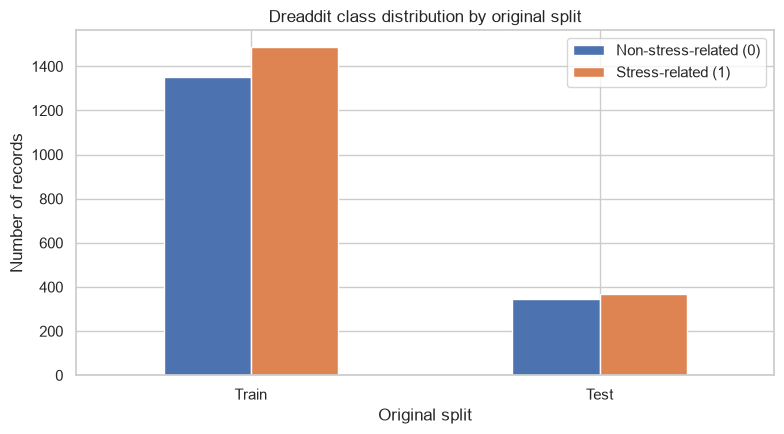

In [16]:
counts = pd.DataFrame({'Train':train.label.value_counts().reindex([0,1],fill_value=0), 'Test':test.label.value_counts().reindex([0,1],fill_value=0)})
counts.index = ['Non-stress-related (0)', 'Stress-related (1)']
percentages = counts.div(counts.sum(axis=0),axis=1).mul(100).round(2)
display(counts)
display(percentages)
counts.to_csv(OUT_METRICS/'class_counts.csv')
percentages.to_csv(OUT_METRICS/'class_percentages.csv')
ax = counts.T.plot(kind='bar', figsize=(8,4.5), rot=0)
ax.set(title='Dreaddit class distribution by original split',ylabel='Number of records',xlabel='Original split')
plt.tight_layout(); plt.savefig(OUT_FIGS/'01_class_distribution.png',dpi=160,bbox_inches='tight');plt.show()

## 4. Text length and basic descriptive statistics

Text lengths reflect dataset structure, **not** severity of stress.


train text character/word summaries:


C:\Users\User\AppData\Local\Temp\ipykernel_9176\1653717576.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  eda[name]=df.assign(text_chars=df.text.astype(str).str.len(), text_words=df.text.astype(str).str.split().str.len())


,text_chars,text_words
count,2838.00,2838.00
mean,448.00,85.67
std,168.93,32.29
min,6.00,1.00
10%,276.00,53.00
25%,339.00,65.00
50%,421.00,80.00
75%,528.75,101.00
90%,660.30,126.30
99%,1004.52,189.63


test text character/word summaries:


C:\Users\User\AppData\Local\Temp\ipykernel_9176\1653717576.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  eda[name]=df.assign(text_chars=df.text.astype(str).str.len(), text_words=df.text.astype(str).str.split().str.len())


,text_chars,text_words
count,715.00,715.00
mean,446.37,85.45
std,164.12,31.23
min,64.00,12.00
10%,276.40,53.00
25%,335.00,65.00
50%,424.00,81.00
75%,524.50,101.00
90%,646.60,126.00
99%,908.44,175.86


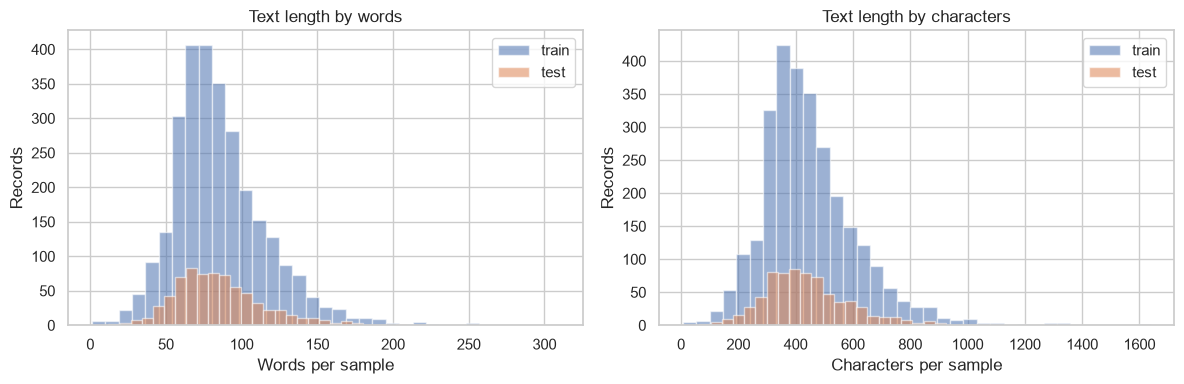

In [17]:
eda={}
for name,df in [('train',train),('test',test)]:
    eda[name]=df.assign(text_chars=df.text.astype(str).str.len(), text_words=df.text.astype(str).str.split().str.len())
    print(name, 'text character/word summaries:')
    display(eda[name][['text_chars','text_words']].describe(percentiles=[.1,.25,.5,.75,.9,.99]).round(2))
summary = pd.concat([eda[s][['text_chars','text_words']].describe().add_prefix(s+'_') for s in ['train','test']],axis=1)
summary.to_csv(OUT_METRICS/'text_length_summary.csv')
fig, axs=plt.subplots(1,2,figsize=(12,4))
for split,df in eda.items():
    axs[0].hist(df['text_words'],bins=35,alpha=.55,label=split)
    axs[1].hist(df['text_chars'],bins=35,alpha=.55,label=split)
axs[0].set(xlabel='Words per sample',ylabel='Records',title='Text length by words')
axs[1].set(xlabel='Characters per sample',ylabel='Records',title='Text length by characters')
for ax in axs:ax.legend()
plt.tight_layout();plt.savefig(OUT_FIGS/'02_text_lengths.png',dpi=160,bbox_inches='tight');plt.show()

## 5. Integrity checks: full duplicates, normalized text, IDs and cross-split overlap

A cross-split text match is a **possible contamination risk** even if post IDs differ. `post_id` may appear multiple times because a source post can contribute multiple text segments. We report both post-level repetition and split overlap.


In [18]:
import re

def normalize_text(series):
    return series.astype('string').fillna('').str.casefold().str.replace(r'\s+', ' ',regex=True).str.strip()

norm_tr=normalize_text(train.text)
norm_te=normalize_text(test.text)
common_text=set(norm_tr)&set(norm_te)
common_post=set(train.post_id.dropna().astype(str))&set(test.post_id.dropna().astype(str)) if 'post_id' in train else set()
common_id=set(train.id.dropna().astype(str))&set(test.id.dropna().astype(str)) if 'id' in train else set()
checks={
 'train_duplicate_full_rows':int(train.duplicated().sum()),
 'test_duplicate_full_rows':int(test.duplicated().sum()),
 'train_duplicate_normalized_text':int(norm_tr.duplicated().sum()),
 'test_duplicate_normalized_text':int(norm_te.duplicated().sum()),
 'cross_split_identical_normalized_texts':len(common_text),
 'cross_split_overlapping_post_ids':len(common_post),
 'cross_split_overlapping_ids':len(common_id),
 'train_duplicate_post_ids':int(train.post_id.astype(str).duplicated().sum()) if 'post_id' in train else None,
 'test_duplicate_post_ids':int(test.post_id.astype(str).duplicated().sum()) if 'post_id' in test else None,
 'train_duplicate_record_ids':int(train.id.astype(str).duplicated().sum()) if 'id' in train else None,
 'test_duplicate_record_ids':int(test.id.astype(str).duplicated().sum()) if 'id' in test else None,
}
display(pd.DataFrame(checks.items(),columns=['check','value']))
# Safe metadata-only evidence; avoid writing raw text to a public repository.
leakage_rows=[]
for v in sorted(common_text):
    tr=train.loc[norm_tr==v]; te=test.loc[norm_te==v]
    leakage_rows.append({'text_sha256':hashlib.sha256(v.encode('utf-8')).hexdigest(), 'train_rows':len(tr),'test_rows':len(te),'train_labels':','.join(map(str,sorted(tr.label.unique()))),'test_labels':','.join(map(str,sorted(te.label.unique())))})
pd.DataFrame(leakage_rows,columns=['text_sha256','train_rows','test_rows','train_labels','test_labels']).to_csv(OUT_METRICS/'cross_split_text_overlap_metadata.csv',index=False)
(OUT_METRICS/'integrity_checks.json').write_text(json.dumps(checks,indent=2),encoding='utf-8')
print('Overlap hashes and label consistency saved; original texts are not exported.')

,check,value
0,train_duplicate_full_rows,0
1,test_duplicate_full_rows,0
2,train_duplicate_normalized_text,18
3,test_duplicate_normalized_text,0
4,cross_split_identical_normalized_texts,3
5,cross_split_overlapping_post_ids,0
6,cross_split_overlapping_ids,0
7,train_duplicate_post_ids,495
8,test_duplicate_post_ids,129
9,train_duplicate_record_ids,0


Overlap hashes and label consistency saved; original texts are not exported.


## 6. Label consistency for repeated text and source posts

Any conflicting labels for identical normalized text should be flagged, not silently corrected.


In [19]:
combined=pd.concat([train.assign(dataset_split='train', normalized_text=norm_tr),test.assign(dataset_split='test',normalized_text=norm_te)],ignore_index=True)
text_conflicts=(combined.groupby('normalized_text')['label'].nunique()>1)
post_conflicts=(combined.groupby('post_id')['label'].nunique()>1) if 'post_id' in combined else pd.Series(dtype=bool)
consistency={'unique_normalized_texts':int(combined.normalized_text.nunique()),'identical_text_with_conflicting_labels':int(text_conflicts.sum()),'post_ids_with_multiple_labels':int(post_conflicts.sum())}
display(pd.DataFrame(consistency.items(),columns=['check','value']))
(OUT_METRICS/'label_consistency.json').write_text(json.dumps(consistency,indent=2),encoding='utf-8')

C:\Users\User\AppData\Local\Temp\ipykernel_9176\1766097164.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  combined=pd.concat([train.assign(dataset_split='train', normalized_text=norm_tr),test.assign(dataset_split='test',normalized_text=norm_te)],ignore_index=True)


,check,value
0,unique_normalized_texts,3532
1,identical_text_with_conflicting_labels,6
2,post_ids_with_multiple_labels,179


124

## 7. Subreddit distribution and potential source confounding

If stress/non-stress labels vary substantially by subreddit, the classifier may learn community cues instead of generalizable stress language. Descriptive association is not proof of causation.


,label_0,label_1,total,stress_fraction
subreddit,,,,
ptsd,297,414,711,0.582278
relationships,387,307,694,0.442363
anxiety,234,416,650,0.640000
domesticviolence,139,249,388,0.641753
assistance,229,126,355,0.354930
survivorsofabuse,172,143,315,0.453968
homeless,139,81,220,0.368182
almosthomeless,40,59,99,0.595960
stress,33,45,78,0.576923


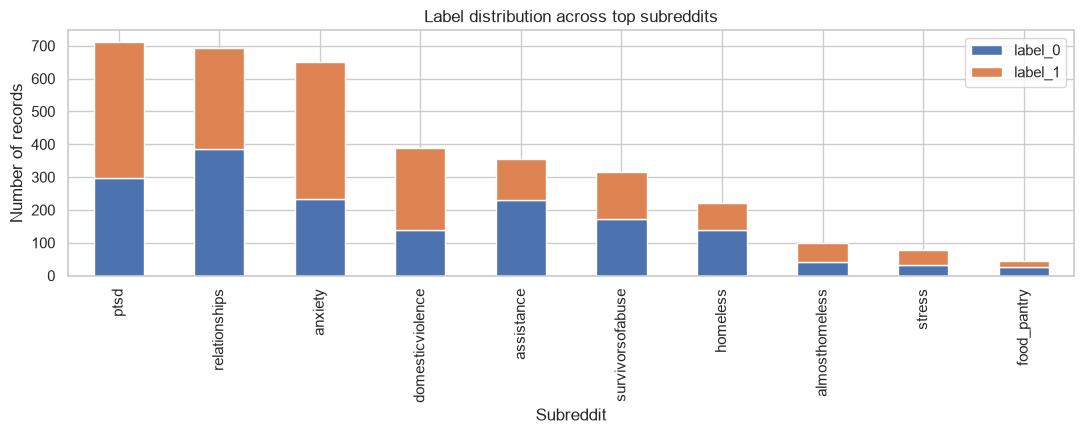

In [20]:
subreddit_counts = pd.crosstab(combined['subreddit'].astype(str),combined['label'])
subreddit_counts.columns=['label_0','label_1'] if len(subreddit_counts.columns)==2 else [f'label_{x}' for x in subreddit_counts.columns]
subreddit_counts['total']=subreddit_counts.sum(axis=1)
subreddit_counts['stress_fraction']=subreddit_counts.get('label_1',0)/subreddit_counts['total']
subreddit_counts.sort_values('total',ascending=False).to_csv(OUT_METRICS/'subreddit_label_distribution.csv')
display(subreddit_counts.sort_values('total',ascending=False).head(15))
top=subreddit_counts.sort_values('total',ascending=False).head(12)
ax=top[['label_0','label_1']].plot(kind='bar',stacked=True,figsize=(11,4.5))
ax.set(xlabel='Subreddit',ylabel='Number of records',title='Label distribution across top subreddits')
plt.tight_layout();plt.savefig(OUT_FIGS/'03_subreddit_class_counts.png',dpi=160,bbox_inches='tight');plt.show()

## 8. Numeric feature quality (no feature selection or leakage-inducing preprocessing)

We describe fields but do **not** choose features based on test labels. Treat `label`, `confidence`, `id`, `post_id`, `sentence_range`, `subreddit` and timestamps carefully: annotation metadata, group IDs, and source metadata can cause invalid shortcuts. Select a feature policy during the methodology step.


In [21]:
numeric=train.select_dtypes(include='number').columns.tolist()
constant_cols=[c for c in train.columns if train[c].nunique(dropna=False)<=1]
inf_counts={s:int(np.isinf(df.select_dtypes(include='number').to_numpy()).sum()) for s,df in [('train',train),('test',test)]}
quality={'constant_columns_train':constant_cols,'infinite_numeric_cells':inf_counts,'numeric_column_count':len(numeric)}
print(json.dumps(quality,indent=2))
(OUT_METRICS/'numeric_quality.json').write_text(json.dumps(quality,indent=2),encoding='utf-8')
interesting=[c for c in ['sentiment','lex_liwc_anx','lex_liwc_sad','lex_liwc_negemo','social_karma','social_num_comments','social_upvote_ratio'] if c in train]
if interesting:
    display(train[interesting].describe().T.round(3))
    train[interesting].describe().T.to_csv(OUT_METRICS/'selected_numeric_summary_train.csv')

{
  "constant_columns_train": [],
  "infinite_numeric_cells": {
    "train": 0,
    "test": 0
  },
  "numeric_column_count": 112
}


,count,mean,std,min,25%,50%,75%,max
sentiment,2838.0,0.041,0.195,-1.00,-0.072,0.045,0.167,1.0
lex_liwc_anx,2838.0,0.914,1.469,0.00,0.000,0.000,1.450,25.0
lex_liwc_sad,2838.0,0.598,1.094,0.00,0.000,0.000,1.050,12.5
lex_liwc_negemo,2838.0,3.305,3.022,0.00,1.140,2.700,4.840,37.5
social_karma,2838.0,18.262,79.419,0.00,2.000,5.000,10.000,1435.0
social_num_comments,2838.0,9.949,21.798,0.00,2.000,5.000,10.000,416.0
social_upvote_ratio,2838.0,0.844,0.175,0.14,0.750,0.890,1.000,1.0


## 9. Date coverage and limits of longitudinal evidence

`social_timestamp` refers to a social-media record. Without a stable, verified user identifier and repeated observations per user, it is **not** an individual mental-health trajectory.


In [22]:
time_summary={}
for name,df in [('train',train),('test',test)]:
    if 'social_timestamp' in df:
        dates=pd.to_datetime(df['social_timestamp'],unit='s',utc=True,errors='coerce')
        time_summary[name]={'valid_timestamps':int(dates.notna().sum()),'invalid_timestamps':int(dates.isna().sum()),'min_utc':str(dates.min()),'max_utc':str(dates.max())}
print(json.dumps(time_summary,indent=2))
(OUT_METRICS/'timestamp_coverage.json').write_text(json.dumps(time_summary,indent=2),encoding='utf-8')

{
  "train": {
    "valid_timestamps": 2838,
    "invalid_timestamps": 0,
    "min_utc": "2017-01-01 12:36:58+00:00",
    "max_utc": "2018-11-19 01:54:20+00:00"
  },
  "test": {
    "valid_timestamps": 715,
    "invalid_timestamps": 0,
    "min_utc": "2017-01-02 04:02:57+00:00",
    "max_utc": "2018-11-18 23:20:24+00:00"
  }
}


328

## 10. Dataset suitability summary and actionable risks

These are analytical conclusions from the dataset structure, not evidence of model performance.


In [23]:
risk_register = pd.DataFrame([
 {'risk':'Cross-split identical text','evidence':f"{checks['cross_split_identical_normalized_texts']} normalized texts shared",'recommended_action':'Identify overlap; plan a contamination-sensitive secondary evaluation without changing the original benchmark split.'},
 {'risk':'Post/source correlations','evidence':f"{checks['train_duplicate_post_ids']} repeated post IDs in train",'recommended_action':'Assess grouped validation in later modeling stage; avoid source-identity leakage.'},
 {'risk':'Subreddit confounding','evidence':f"{train.subreddit.nunique()} training subreddits",'recommended_action':'Evaluate subgroup distributions and report domain generalization limitations.'},
 {'risk':'Annotation metadata leakage','evidence':'confidence and IDs included in CSV','recommended_action':'Do not feed annotation confidence or record IDs to predictive model.'},
 {'risk':'Missing person-level histories','evidence':'No verified user-level longitudinal identifier','recommended_action':'Use clearly marked synthetic sequences for scoring mechanics, not real-world temporal validation.'},
 {'risk':'Clinical overinterpretation','evidence':'Binary stress-related text annotation','recommended_action':'Do not label model output a diagnosis or validated individual mental-health risk.'},
 {'risk':'Data usage rights','evidence':'CSV files alone do not prove redistribution rights','recommended_action':'Verify original dataset license, research terms and privacy obligations.'},
])
display(risk_register)
risk_register.to_csv(OUT_METRICS/'pp1_data_risk_register.csv',index=False)


,risk,evidence,recommended_action
0,Cross-split identical text,3 normalized texts shared,Identify overlap; plan a contamination-sensiti...
1,Post/source correlations,495 repeated post IDs in train,Assess grouped validation in later modeling st...
2,Subreddit confounding,10 training subreddits,Evaluate subgroup distributions and report dom...
3,Annotation metadata leakage,confidence and IDs included in CSV,Do not feed annotation confidence or record ID...
4,Missing person-level histories,No verified user-level longitudinal identifier,Use clearly marked synthetic sequences for sco...
5,Clinical overinterpretation,Binary stress-related text annotation,Do not label model output a diagnosis or valid...
6,Data usage rights,CSV files alone do not prove redistribution ri...,"Verify original dataset license, research term..."


## 11. Export reproducible PP1 summary

The report includes file hashes and counts but avoids sharing raw social-media text.


In [24]:
report={
 'project':'J26-IT-388 Component 4',
 'notebook':'01_dataset_validation',
 'generated_at_utc':datetime.now(timezone.utc).isoformat(),
 'source_files':manifest,
 'shape':{'train':[int(v) for v in train.shape],'test':[int(v) for v in test.shape]},
 'column_set_equal':not only_train and not only_test,
 'column_order_equal':list(train.columns)==list(test.columns),
 'null_cells':{'train':int(train.isna().sum().sum()),'test':int(test.isna().sum().sum())},
 'blank_text_rows':{'train':blanks['train'].get('text',0),'test':blanks['test'].get('text',0)},
 'class_counts':{s:{str(k):int(v) for k,v in df.label.value_counts().items()} for s,df in [('train',train),('test',test)]},
 'integrity':checks,'consistency':consistency,'numeric_quality':quality,'timestamps':time_summary,
 'limitations':['Stress text annotations are not clinical diagnoses','No verified user-level longitudinal history','No model was trained or evaluated in this notebook']
}
(OUT_METRICS/'dataset_quality_report.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
print('Saved report:', OUT_METRICS/'dataset_quality_report.json')
print('Metrics files:'); print(*sorted(p.name for p in OUT_METRICS.iterdir()),sep='\n - ')
print('Figures:'); print(*sorted(p.name for p in OUT_FIGS.iterdir()),sep='\n - ')
print('Notebook 01 finished. NO MODEL TRAINED.')

Saved report: E:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388\experiments\metrics\notebook01\dataset_quality_report.json
Metrics files:
class_counts.csv
 - class_percentages.csv
 - column_schema.csv
 - cross_split_text_overlap_metadata.csv
 - dataset_quality_report.json
 - integrity_checks.json
 - label_consistency.json
 - numeric_quality.json
 - pp1_data_risk_register.csv
 - selected_numeric_summary_train.csv
 - source_manifest.json
 - subreddit_label_distribution.csv
 - text_length_summary.csv
 - timestamp_coverage.json
Figures:
01_class_distribution.png
 - 02_text_lengths.png
 - 03_subreddit_class_counts.png
Notebook 01 finished. NO MODEL TRAINED.


## Notebook 01 — Completion criteria

- All cells run successfully on the **original** CSV files.
- Save the notebook, JSON/CSV quality metrics and figures as PP1 evidence.
- Review cross-split exact-text overlaps, label consistency and source confounding before later model training.
- Do **not** claim any accuracy/F1 from this notebook; those are model evaluation metrics for a later stage.
- When sharing outputs publicly, verify dataset permissions and avoid exposing individual post content.
